In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib

print("Libraries imported successfully")

Libraries imported successfully


In [7]:
df = pd.read_csv("../data/reviews.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10000, 5)


,review_id,review_text,sentiment,category,source
0,1,This product exceeded my expectations in sever...,Positive,Books,Online Store
1,2,The item is uncomfortable to use and poorly de...,Negative,Books,Online Store
2,3,The product comes with a charging adapter and ...,Neutral,Travel,Customer Survey
3,4,Customer support was slow and did not solve my...,Negative,Home & Kitchen,Website
4,5,"The design is simple, attractive, and comforta...",Positive,Sports,Online Store


In [8]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

print("\nCategory Distribution:")
print(df["category"].value_counts())

print("\nSource Distribution:")
print(df["source"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    10000 non-null  int64
 1   review_text  10000 non-null  str  
 2   sentiment    10000 non-null  str  
 3   category     10000 non-null  str  
 4   source       10000 non-null  str  
dtypes: int64(1), str(4)
memory usage: 1.5 MB

Missing Values:
review_id      0
review_text    0
sentiment      0
category       0
source         0
dtype: int64

Duplicate Rows:
0

Sentiment Distribution:
sentiment
Positive    3334
Negative    3333
Neutral     3333
Name: count, dtype: int64

Category Distribution:
category
Travel            1305
Clothing          1288
Sports            1278
Beauty            1272
Home & Kitchen    1245
Electronics       1239
Food & Grocery    1205
Books             1168
Name: count, dtype: int64

Source Distribution:
source
Online Store       2590
Customer Survey

In [9]:
print(df.columns)
print(df.shape)
print(df.head())

Index(['review_id', 'review_text', 'sentiment', 'category', 'source'], dtype='str')
(10000, 5)
   review_id                                        review_text sentiment  \
0          1  This product exceeded my expectations in sever...  Positive   
1          2  The item is uncomfortable to use and poorly de...  Negative   
2          3  The product comes with a charging adapter and ...   Neutral   
3          4  Customer support was slow and did not solve my...  Negative   
4          5  The design is simple, attractive, and comforta...  Positive   

         category           source  
0           Books     Online Store  
1           Books     Online Store  
2          Travel  Customer Survey  
3  Home & Kitchen          Website  
4          Sports     Online Store  


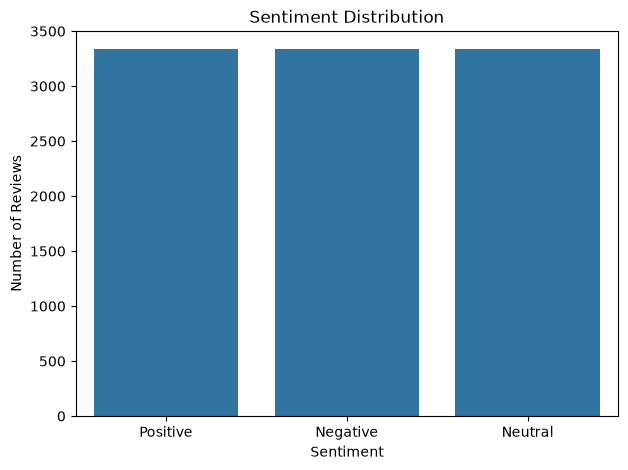

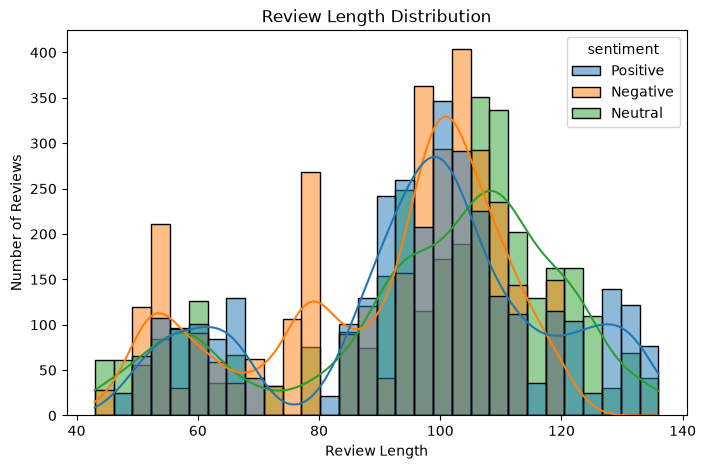

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="sentiment")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

df["review_length"] = df["review_text"].astype(str).str.len()

plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="review_length",
    hue="sentiment",
    bins=30,
    kde=True
)

plt.title("Review Length Distribution")
plt.xlabel("Review Length")
plt.ylabel("Number of Reviews")
plt.show()

In [11]:
def clean_text(text):
    text = str(text).lower()
    text = text.strip()
    return text

df["clean_text"] = df["review_text"].apply(clean_text)

df[["review_text", "clean_text"]].head()

,review_text,clean_text
0,This product exceeded my expectations in sever...,this product exceeded my expectations in sever...
1,The item is uncomfortable to use and poorly de...,the item is uncomfortable to use and poorly de...
2,The product comes with a charging adapter and ...,the product comes with a charging adapter and ...
3,Customer support was slow and did not solve my...,customer support was slow and did not solve my...
4,"The design is simple, attractive, and comforta...","the design is simple, attractive, and comforta..."


In [12]:
# Get unique review texts
unique_reviews = df["clean_text"].drop_duplicates().tolist()

# Split unique reviews into training and testing sets
train_reviews, test_reviews = train_test_split(
    unique_reviews,
    test_size=0.2,
    random_state=42
)

# Create training and testing DataFrames
train_df = df[df["clean_text"].isin(train_reviews)].copy()
test_df = df[df["clean_text"].isin(test_reviews)].copy()

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print("\nUnique training reviews:", train_df["clean_text"].nunique())
print("Unique testing reviews:", test_df["clean_text"].nunique())

Training samples: 8006
Testing samples: 1994

Unique training reviews: 240
Unique testing reviews: 60


In [13]:
X_train = train_df["clean_text"]
y_train = train_df["sentiment"]

X_test = test_df["clean_text"]
y_test = test_df["sentiment"]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

tfidf_logistic = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        max_features=5000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000
    ))
])

tfidf_logistic.fit(X_train, y_train)

y_pred = tfidf_logistic.predict(X_test)

print(classification_report(y_test, y_pred))

Training data: (8006,)
Testing data: (1994,)
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       618
     Neutral       1.00      1.00      1.00       563
    Positive       1.00      1.00      1.00       813

    accuracy                           1.00      1994
   macro avg       1.00      1.00      1.00      1994
weighted avg       1.00      1.00      1.00      1994



In [14]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=5000
        )),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),

    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=5000
        )),
        ("classifier", MultinomialNB())
    ]),

    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=5000
        )),
        ("classifier", LinearSVC())
    ])
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="weighted"),
        "Recall": recall_score(y_test, predictions, average="weighted"),
        "F1 Score": f1_score(y_test, predictions, average="weighted")
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Naive Bayes,1.0,1.0,1.0,1.0
2,Linear SVM,1.0,1.0,1.0,1.0


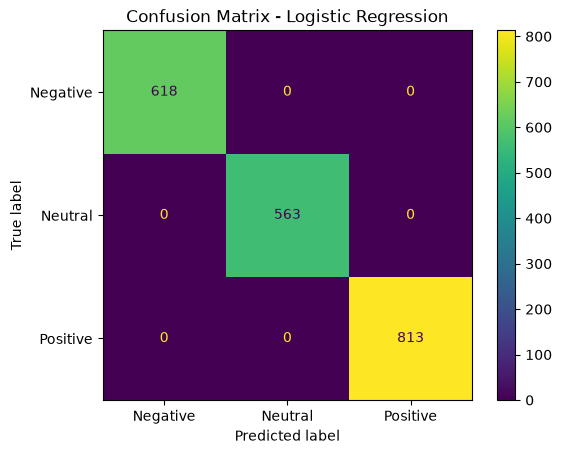

Cross-validation scores: [1. 1. 1. 1. 1.]
Mean CV F1 Score: 1.0


In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

final_model = models["Logistic Regression"]

final_predictions = final_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=["Negative", "Neutral", "Positive"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot()

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    final_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1_weighted"
)

print("Cross-validation scores:", cv_scores)
print("Mean CV F1 Score:", cv_scores.mean())

In [16]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__max_features": [3000, 5000],
    "classifier__C": [0.1, 1, 10]
}

grid_search = GridSearchCV(
    final_model,
    param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV F1 Score:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__C': 0.1, 'tfidf__max_features': 3000, 'tfidf__ngram_range': (1, 1)}

Best CV F1 Score:
1.0


In [17]:
best_model = grid_search.best_estimator_

best_model.fit(X_train, y_train)

final_predictions = best_model.predict(X_test)

print(classification_report(y_test, final_predictions))

              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       618
     Neutral       1.00      1.00      1.00       563
    Positive       1.00      1.00      1.00       813

    accuracy                           1.00      1994
   macro avg       1.00      1.00      1.00      1994
weighted avg       1.00      1.00      1.00      1994



In [18]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

model_path = "../models/sentiment_pipeline.pkl"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: ../models/sentiment_pipeline.pkl


In [2]:
loaded_model = joblib.load("../models/sentiment_pipeline.pkl")

test_reviews = [
    "The product is excellent and I am very happy with it.",
    "The product is terrible and completely disappointing.",
    "The product is okay, nothing special."
]

predictions = loaded_model.predict(test_reviews)

for review, prediction in zip(test_reviews, predictions):
    print(f"Review: {review}")
    print(f"Prediction: {prediction}")
    print()

loaded_model = joblib.load("../models/sentiment_pipeline.pkl")

test = ["This product is terrible. I hate it."]

print("Prediction:", loaded_model.predict(test)[0])
print("Probabilities:", loaded_model.predict_proba(test)[0])
print("Classes:", loaded_model.classes_)

Review: The product is excellent and I am very happy with it.
Prediction: Positive

Review: The product is terrible and completely disappointing.
Prediction: Neutral

Review: The product is okay, nothing special.
Prediction: Neutral

Prediction: Positive
Probabilities: [0.12598578 0.27179535 0.60221888]
Classes: ['Negative' 'Neutral' 'Positive']
